In [2]:
import numpy as np
import matplotlib.pyplot as plt

## CIs

In [3]:
def get_bernstein_radii(sigma, B, n_array, alpha):
    return sigma*np.sqrt(2 * np.log(2 / alpha) / n_array) + (2*B*np.log(2/alpha))/(3*n_array)
    
def get_hoeffding_radii(B, n_array, alpha):
    return B*np.sqrt(2 * np.log(2 / alpha) / n_array)



array([ 201,  202,  203, ..., 3998, 3999, 4000])

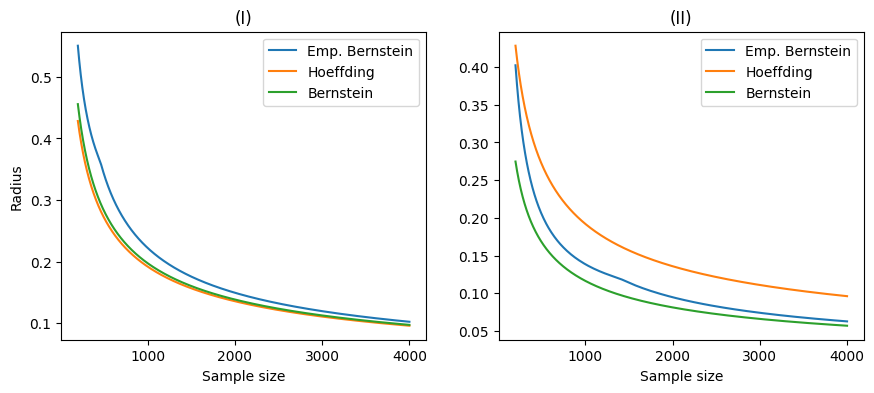

In [5]:
plt.rcParams["figure.figsize"] = (16,4)

d = 5

min_sample_size = 200

experiment_type_list = ["bernoulli", "beta", "uniform"]
experiment_type_list = ["bernoulli", "uniform"]
var_beta = 10*30/((10 + 30)**2 * (10 + 30 + 1))
sigma_dict = {"bernoulli": np.sqrt(d), "beta": np.sqrt(d*var_beta), "uniform": np.sqrt(d/3)}
name_list = ["(I)", "(II)", "(III)"]

for k, experiment_type in enumerate(experiment_type_list):
    plt.subplot(1, 3, k+1)
    experiment_type_name = experiment_type + str(d)

    m = np.load("../data/bernstein_hoeffding/CI/" + experiment_type_name + ".npy")
    n = m.shape[1]
    B = np.sqrt(d)

    emp_bernstein_means, emp_bernstein_radii, hoeffding_means, hoeffding_radii = m[:, :, 0:d], m[:, :, d:d+1], m[:, :, d+1:2*d+1], m[:, :, 2*d+1:]

    emp_bernstein_radii[emp_bernstein_radii > np.sqrt(2)*B] = B
    hoeffding_radii[hoeffding_radii > B] = B

    idx = np.arange(n) + 1
    emp_bernstein_average_radii = np.mean(emp_bernstein_radii, 0)[:, 0]
    hoeffding_average_radii = np.mean(hoeffding_radii, 0)[:, 0]

    plt.plot(idx[min_sample_size:], emp_bernstein_average_radii[min_sample_size:], label = "Emp. Bernstein")
    #plt.plot(idx[min_sample_size:], hoeffding_average_radii[min_sample_size:], label = "Hoeffding")
    

    alpha = 0.05
    # n_array = idx[min_sample_size:]
    hoeffding_radii = get_hoeffding_radii(B, idx, alpha)
    plt.plot(idx[min_sample_size:], hoeffding_radii[min_sample_size:], label = "Hoeffding")
    sigma = sigma_dict[experiment_type]
    bernstein_radii = get_bernstein_radii(sigma, B, idx, alpha)
    plt.plot(idx[min_sample_size:], bernstein_radii[min_sample_size:], label = "Bernstein")

    plt.legend()
    plt.title(name_list[k])

    if k == 0:
        plt.ylabel("Radius")
    plt.xlabel("Sample size")

plt.savefig("../plots/bernstein_hoeffding/" + "ci_three_plots", bbox_inches='tight', dpi=400)


np.sqrt(n)*hoeffding_average_radii[-1], np.sqrt(n)*emp_bernstein_average_radii[-1]
idx[min_sample_size:]